<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan2/BTOL/MachineLearningT2_BTVN_Bai1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kich thuoc du lieu: (150, 4)
Cac loai hoa: ['setosa' 'versicolor' 'virginica']
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  
Gia tri thieu: 0

SO SANH K:
         Xu ly  K  Accuracy
Chua chuan hoa  1  0.966667
Chua chuan hoa  

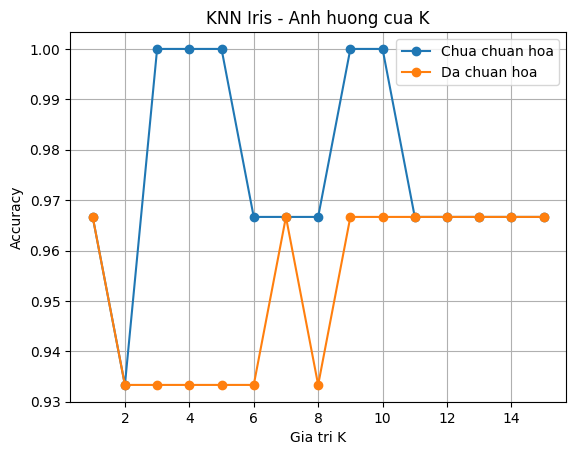


K toi uu: 3
CV Accuracy: 0.9666666666666668
Test Accuracy: 0.9333333333333333

 Euclidean
Ma tran nham lan:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


 Manhattan
Ma tran nham lan:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


 Minkowski p=3
Ma tran n

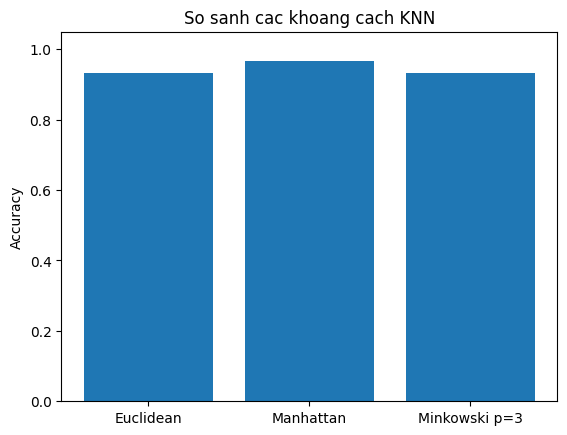

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Nap du lieu Iris
iris = load_iris()
X, y = iris.data, iris.target

print("Kich thuoc du lieu:", X.shape)
print("Cac loai hoa:", iris.target_names)
print(pd.DataFrame(X, columns=iris.feature_names).describe())
print("Gia tri thieu:", pd.DataFrame(X).isna().sum().sum())

# 2. Chia 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Chuan hoa du lieu
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 4. Thu K tu 1 den 15
rows = []

for name, train, test in [
    ("Chua chuan hoa", X_train, X_test),
    ("Da chuan hoa", X_train_s, X_test_s)
]:
    for k in range(1, 16):
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(train, y_train)
        pred = model.predict(test)

        rows.append({
            "Xu ly": name,
            "K": k,
            "Accuracy": accuracy_score(y_test, pred)
        })

result = pd.DataFrame(rows)
print("\nSO SANH K:")
print(result.to_string(index=False))

for name, group in result.groupby("Xu ly"):
    plt.plot(group["K"], group["Accuracy"], marker="o", label=name)

plt.xlabel("Gia tri K")
plt.ylabel("Accuracy")
plt.title("KNN Iris - Anh huong cua K")
plt.legend()
plt.grid()
plt.show()

# 5. Tim K toi uu tren tap train bang cross-validation
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    pipe,
    {"knn__n_neighbors": list(range(1, 16))},
    cv=cv,
    scoring="accuracy"
)
grid.fit(X_train, y_train)

best_k = grid.best_params_["knn__n_neighbors"]

print("\nK toi uu:", best_k)
print("CV Accuracy:", grid.best_score_)
print("Test Accuracy:", grid.score(X_test, y_test))

# 6. So sanh cac khoang cach
rows = []

for name, p in [
    ("Euclidean", 2),
    ("Manhattan", 1),
    ("Minkowski p=3", 3)
]:
    model = KNeighborsClassifier(
        n_neighbors=best_k, metric="minkowski", p=p
    )
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)

    rows.append({
        "Khoang cach": name,
        "Accuracy": accuracy_score(y_test, pred)
    })

    print("\n", name)
    print("Ma tran nham lan:")
    print(confusion_matrix(y_test, pred))
    print(classification_report(
        y_test, pred, target_names=iris.target_names,
        zero_division=0
    ))

result2 = pd.DataFrame(rows)
print("\nBANG SO SANH KHOANG CACH:")
print(result2)

plt.bar(result2["Khoang cach"], result2["Accuracy"])
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("So sanh cac khoang cach KNN")
plt.show()
